<a href="https://colab.research.google.com/github/Murcha1990/ML_AI26/blob/main/homeworks/base/HW1_Regression_with_inference_base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Домашнее задание №1 (base)**

В этом домашнем задании вам будет необходимо:
*  обучить модель регрессии для предсказания стоимости автомобилей;

**Оценивание**

Максимальная оценка за ДЗ — **10 баллов**:
- Части 1–4 (EDA, модели, категориальные признаки, бизнес-метрика) — 5 баллов;
- Часть 5, оформление репозитория — 2 балла;
- Часть 6, Streamlit-приложение — 3 балла.

**Дедлайн: 2 декабря**

**Примечание**

В каждой части оцениваются как код, **так и ответы на вопросы.**

Если нет одного и/или другого, то часть баллов за соответствующее задание снимается.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import seaborn as sns
from ydata_profiling import ProfileReport

from sklearn.linear_model import LinearRegression, Lasso, ElasticNet, Ridge
from sklearn.metrics import r2_score, mean_squared_error as MSE
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # для OHE можно использовать и pd.get_dummies

random.seed(42)
np.random.seed(42)

Давайте зафиксируем важный момент.

**Задание 0 (0 баллов).**
Изучите и ответьте на вопрос: для чего фиксируем сиды в домашках?

Чтобы гарантировать воспроизводимость результатов

# **Часть 1 | EDA и визуализация**

Первая часть состоит из классических шагов EDA:

- Базовый EDA и обработка признаков (1.5 балла)
- Визуализации признаков и их анализ (1 балл)

Всего за эту часть можно набрать 2.5 балла.

## **Простейший EDA и обработка признаков (1.5 балла)**

In [2]:
import ssl

ssl._create_default_https_context = ssl._create_unverified_context

In [3]:
df_train = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_train.csv')
df_test = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_test.csv')

print("Train data shape:", df_train.shape)
print("Test data shape: ", df_test.shape)

Train data shape: (6999, 13)
Test data shape:  (1000, 13)


### **Задание 1 (0.45 балла)**

Вы уже встречались с pandas в первой половине семестра. Теперь будем постоянно (кроме некоторых случаев) использовать его для анализа данных и наслаивать навыки. Выполните операции, направленные на практику основных действий с `pandas`:

**0.1 балла**
- [x] Отобразите 30 случайных строк тренировочного датасета.
- [x] Отобразите первые 5 и последние 5 объектов тестового датасета
- [x] Посмотрите, есть ли в датасете пропуски. Запишите/выведите названия колонок, для которых есть пропущенные значения
- [x] Посмотрите, есть ли в данных явные дубликаты


**0.2 балла**
Ответьте на вопросы:
- [x] О чём можно сделать выводы, используя случайные/верхние/нижние строки? А о чем нельзя?
- [x] Достаточно ли метода duplicated для анализа дубликатов? Почему?

**0.15 балла**
- [x] Постройте дашборд, используя [ydata-profiling](https://github.com/ydataai/ydata-profiling)

In [4]:
# 30 случайных строк
df_train.sample(30)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
6565,Renault KWID Climber 1.0 MT BSIV,2019,300000,35000,Petrol,Individual,Manual,First Owner,23.01 kmpl,999 CC,67 bhp,91Nm@ 4250rpm,5.0
2943,Maruti Wagon R LXI,2013,225000,58343,Petrol,Trustmark Dealer,Manual,First Owner,21.79 kmpl,998 CC,67.05 bhp,90Nm@ 3500rpm,5.0
2024,Hyundai i20 Asta 1.2,2013,360000,30000,Petrol,Individual,Manual,First Owner,18.5 kmpl,1197 CC,82.85 bhp,113.7Nm@ 4000rpm,5.0
263,Hyundai i20 1.2 Asta,2010,300000,70000,Petrol,Individual,Manual,First Owner,17.0 kmpl,1197 CC,80 bhp,"11.4 kgm at 4,000 rpm",5.0
4586,Skoda Octavia L and K 1.9 TDI MT,2005,250000,120000,Diesel,Individual,Manual,Third Owner,16.4 kmpl,1896 CC,90 bhp,"21.4@ 1,900(kgm@ rpm)",5.0
4479,Maruti Ciaz ZXi,2016,700000,20000,Petrol,Individual,Manual,First Owner,20.73 kmpl,1373 CC,91.1 bhp,130Nm@ 4000rpm,5.0
4881,Hyundai Grand i10 1.2 Kappa Magna BSIV,2017,445000,27000,Petrol,Individual,Manual,First Owner,18.9 kmpl,1197 CC,81.86 bhp,113.75nm@ 4000rpm,5.0
3583,Ford Ecosport 1.5 DV5 MT Trend,2016,515000,68609,Diesel,Dealer,Manual,First Owner,22.7 kmpl,1498 CC,89.84 bhp,204Nm@ 2000-2750rpm,5.0
6361,Hyundai Verna 1.4 VTVT,2014,500000,33400,Petrol,Individual,Manual,First Owner,17.43 kmpl,1396 CC,105.5 bhp,135.3Nm@ 5000rpm,5.0
4108,Hyundai i20 Era 1.2,2015,490000,45900,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0


In [5]:
#первые 5
df_test.head(5)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Mahindra Xylo E4 BS IV,2010,229999,168000,Diesel,Individual,Manual,First Owner,14.0 kmpl,2498 CC,112 bhp,260 Nm at 1800-2200 rpm,7.0
1,Tata Nexon 1.5 Revotorq XE,2017,665000,25000,Diesel,Individual,Manual,First Owner,21.5 kmpl,1497 CC,108.5 bhp,260Nm@ 1500-2750rpm,5.0
2,Honda Civic 1.8 S AT,2007,175000,218463,Petrol,Individual,Automatic,First Owner,12.9 kmpl,1799 CC,130 bhp,172Nm@ 4300rpm,5.0
3,Honda City i DTEC VX,2015,635000,173000,Diesel,Individual,Manual,First Owner,25.1 kmpl,1498 CC,98.6 bhp,200Nm@ 1750rpm,5.0
4,Tata Indica Vista Aura 1.2 Safire BSIV,2011,130000,70000,Petrol,Individual,Manual,Second Owner,16.5 kmpl,1172 CC,65 bhp,96 Nm at 3000 rpm,5.0


In [6]:
#последние 5
df_test.tail(5)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
995,Hyundai i10 Magna 1.1L,2008,250000,100000,Petrol,Individual,Manual,Second Owner,19.81 kmpl,1086 CC,68.05 bhp,99.04Nm@ 4500rpm,5.0
996,Hyundai i20 2015-2017 Sportz 1.2,2017,440000,50000,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0
997,Hyundai i20 Era Diesel,2009,340000,40000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
998,Hyundai i10 Asta,2012,350000,25000,Petrol,Individual,Manual,First Owner,20.36 kmpl,1197 CC,78.9 bhp,111.8Nm@ 4000rpm,5.0
999,Honda City i DTec SV,2016,700000,110000,Diesel,Individual,Manual,First Owner,26.0 kmpl,1498 CC,98.6 bhp,200Nm@ 1750rpm,5.0


In [7]:
# Количество пропусков в признаках
df_train.isna().sum()

name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          202
engine           202
max_power        196
torque           203
seats            202
dtype: int64

In [8]:
#Какие-то дубли точно есть
df_train.duplicated().sum()

985

In [9]:
df_train.dtypes

name              object
year               int64
selling_price      int64
km_driven          int64
fuel              object
seller_type       object
transmission      object
owner             object
mileage           object
engine            object
max_power         object
torque            object
seats            float64
dtype: object

**О чём можно сделать выводы, используя случайные/верхние/нижние строки? А о чем нельзя?**

Мало о чем можно сделать выводы. Только в общих чертах понять как выглядят данные и как их предстоит предобрабатывать - типы можно посмотреть и иначе, а вот понять что в действительности из себя предстваляет обджект-фича легче всего посмотрев на нее (это рейтинг, бинарное да-нет, или json). 

Помимо этого можно увидеть значительное дублирование в фичах и дополнительно исследовать этот вопрос, чтобы в конечном счете оставить что-то одно

Можно заметить сранивая head и tail что в какой-то момент (в случае если строки отсортированы по дате) данные перестали (или начали) заполняться

В любом случае все зацепки из такого беглого обзора необходимо проверять

**Достаточно ли метода duplicated для анализа дубликатов? Почему?**

duplicated позволяет выделить только полные дубликаты (значения и форматирование) - этого в реальности часто недостаточно. Бывают разные форматирования, бывают дополнительные id из внешних систем которые могут отличаться, при том что это одна и та же сущность. Могут быть одинаковые записи за разные периоды - что в контексте большинства тоже может считаться дубликатом, но duplicated нам не поможет

Подсмотрел дальше - да, а еще может быть разный таргет. А еще может быть что кто-то плохо склеил таблицы и появился какой-то признак который не позволяет так легко распознать дубли в дублях


In [10]:
import warnings

warnings.filterwarnings("ignore")

In [11]:
from ydata_profiling import ProfileReport
profile_train = ProfileReport(df_train, title="Train Report")
profile_test = ProfileReport(df_test, title="Test Report")

In [12]:
profile_train.compare(profile_test)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

### **Задание 2 (0.5 балла)**

На прошлом шаге вы рассмотрели дубликаты. Однако дубликат может быть связан не только с полным повторением информации в нескольких строках, но и частичным. Например, объект мог быть внесён в базу данных с разным значением целевой переменной. В этом шаге займемся такими дублями!

**Ваши действия:**

- [X] Посмотрите, есть ли в трейне объекты с одинаковым признаковым описанием (целевую переменную следует исключить). Если есть, то сколько? (0.1 балла)
- [X] Отобразите такие объекты (0.15 балла)
- [X] Удалите повторяющиеся строки. Если при одинаковом признаковом описании цены на автомобили отличаются, то оставьте первую строку по этому автомобилю (0.15 балла)
- [X]  Обновите индексы строк таким образом, чтобы они шли от 0 без пропусков (0.1 балла)


In [13]:
#без таргета стало больше, значит среди 1159 дубликатов 1159 - 985 объектов где отличался только таргет
df_train.drop(columns='selling_price').duplicated().sum()

1159

In [14]:
df_train[df_train.drop(columns='selling_price').duplicated()].sort_values('name')

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
6307,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,15.73 kmpl,1968 CC,174.33 bhp,380Nm@ 1750-2500rpm,5.0
6704,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,13.22 kmpl,2967 CC,241.4 bhp,580Nm@ 1400-3250rpm,5.0
6640,Audi Q5 35TDI Premium Plus,2018,3975000,31800,Diesel,Dealer,Automatic,First Owner,17.01 kmpl,1968 CC,188 bhp,400nm@ 1750-3000rpm,5.0
1595,Audi Q5 35TDI Premium Plus,2018,3975000,31800,Diesel,Dealer,Automatic,First Owner,17.01 kmpl,1968 CC,188 bhp,400nm@ 1750-3000rpm,5.0
2787,Audi Q5 35TDI Premium Plus,2018,3975000,31800,Diesel,Dealer,Automatic,First Owner,17.01 kmpl,1968 CC,188 bhp,400nm@ 1750-3000rpm,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6778,Volvo XC40 D4 Inscription BSIV,2019,3800000,20000,Diesel,Individual,Automatic,First Owner,18.0 kmpl,1969 CC,190 bhp,400Nm,5.0
3623,Volvo XC40 D4 Inscription BSIV,2019,3800000,20000,Diesel,Individual,Automatic,First Owner,18.0 kmpl,1969 CC,190 bhp,400Nm,5.0
2293,Volvo XC40 D4 Inscription BSIV,2019,3800000,20000,Diesel,Individual,Automatic,First Owner,18.0 kmpl,1969 CC,190 bhp,400Nm,5.0
5652,Volvo XC40 D4 Inscription BSIV,2019,3800000,20000,Diesel,Individual,Automatic,First Owner,18.0 kmpl,1969 CC,190 bhp,400Nm,5.0


In [15]:
df_train.drop_duplicates(df_train.drop(columns='selling_price').columns, keep = 'first', ignore_index=True, inplace=True)

In [16]:
assert df_train.shape == (5840, 13)

Отлично! Мы избавились от маленьких и явных проблем. Теперь перейдем к более сложным недостаткам полученной таблицы.

### **Задание 3 (0.25 балла)**

Вы могли заметить, что с признаками ``mileage, engine, max_power и torque`` всё не очень хорошо. Они распознаются как строки (можно убедиться в этом, вызвав `data.dtypes`). Однако эти переменные не являются категориальными — они — числа. Соответственно, нужно привести их к числовому виду.

**Задача:**
* [X] Уберите единицы измерения для признаков ``mileage, engine, max_power``.
* [X] Приведите тип данных к ``float``.
* [X] Удалите столбец ``torque``


**Важно**
- Все действия нужно производить над обоими датасетами — `train` и `test`.
- Столбец ``torque`` мы удаляем для простоты. В идеальном случае, его также стоило бы предобработать.

In [17]:
#Что-то упало в max_power
def strange_cases(x):
    try:
        return float(x.split()[0])
    except:
        print('Странный кейс:', x)
        return np.NaN

def to_float(df, columns):
    for column in columns:
        df.loc[~df[column].isna(), column] = df.loc[~df[column].isna(), column].apply(lambda x: strange_cases(x))
        df[column] = df[column].astype('float')

In [18]:
to_float(df_train, ['mileage', 'engine', 'max_power'])
to_float(df_test, ['mileage', 'engine', 'max_power'])

Странный кейс:  bhp


Ну ничего страшного, в одном объекте не было значения, заменил на нан

In [19]:
df_train.drop(columns='torque', inplace=True)
df_test.drop(columns='torque', inplace=True)

### **Задание 4 (0.15 балла)**

В Задании 1 мы обнаружили пропуски. Давайте избавимся от них.

**Шаг 1 (0.05 балла)**
- [X] Заполните пропуски в столбцах медианами. Убедитесь, что после заполнения пропусков не осталось. Заполнение пропусков проводите для обоих наборов данных, если необходимо

**Важно!**

При заполнении пропусков и в тестовом, и тренировочном наборах данных вы определяетесь со стратегией предобработки пропущенных значений при потенциальной работе модели.

Так как в теоретическом случае вы не имеете доступа к тестовой выборке, то заполняемое значение (у нас — медиана) вы считаете по *тренировочному* набору данных и им же заполняете *тестовый*.

In [20]:
medians = df_train.median(numeric_only=True)

In [21]:
df_train.fillna(medians, inplace=True)
df_test.fillna(medians, inplace=True)

In [22]:
df_train[df_train.isna()].sum()

name               0
year             0.0
selling_price    0.0
km_driven        0.0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          0.0
engine           0.0
max_power        0.0
seats            0.0
dtype: object

In [23]:
df_test[df_test.isna()].sum()

name               0
year             0.0
selling_price    0.0
km_driven        0.0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          0.0
engine           0.0
max_power        0.0
seats            0.0
dtype: object

**Шаг 2 (0.1 балла)**

Теперь, когда не осталось пропусков, давайте преобразуем столбцы к более подходящим типам. А именно столбцы ``engine`` и ``seats`` приведём к `int`.

- [X] Осуществите приведение столбцов к необходимому типу.

In [24]:
for column in ['engine', 'seats']:
    df_train[column] = df_train[column].astype('int')
    df_test[column] = df_test[column].astype('int')

### **Задание 5 (0.15 балла)**

Отлично! Мы провели "косметическую" предобработку и теперь готовы сделать важный шаг в контексте анализа данных. А именно — посмотреть на статистики!

**Ваша задача:**
- [X] Посчитайте основные статистики по числовым столбцам для трейна и теста
- [X] Посчитайте основные статистики по категориальным столбцам для трейна и теста
- [X] Сделайте вывод.

**Подсказка:**

Используйте ``.describe()`` с нужным(и) аргументом(-ами).

**Примечание:**

Более корректно рассматривать статистики до заполнения пропусков и после, чтобы убедиться, что мы не внесли каких-либо серьезных сдвигов в изначальные распределения.

In [25]:
df_train.describe()

,year,selling_price,km_driven,mileage,engine,max_power,seats
count,5840.000000,5.840000e+03,5.840000e+03,5840.000000,5840.000000,5840.000000,5840.000000
mean,2013.428425,5.229601e+05,7.395224e+04,19.430841,1429.448973,87.906371,5.426712
std,4.095622,5.354320e+05,6.007114e+04,3.985973,485.662834,31.640418,0.982344
min,1983.000000,2.999900e+04,1.000000e+00,0.000000,624.000000,0.000000,2.000000
25%,2011.000000,2.500000e+05,3.900000e+04,16.950000,1197.000000,68.000000,5.000000
50%,2014.000000,4.050000e+05,7.000000e+04,19.370000,1248.000000,81.860000,5.000000
75%,2017.000000,6.400000e+05,1.000000e+05,22.300000,1498.000000,99.000000,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,42.000000,3604.000000,400.000000,14.000000


In [26]:
df_test.describe()

,year,selling_price,km_driven,mileage,engine,max_power,seats
count,1000.000000,1.000000e+03,1000.000000,1000.00000,1000.00000,1000.000000,1000.000000
mean,2013.681000,6.179010e+05,71393.341000,19.33881,1454.87600,90.841670,5.403000
std,4.012149,7.585539e+05,48486.218662,3.95175,521.99574,34.893389,0.912921
min,1995.000000,3.100000e+04,1303.000000,0.00000,624.00000,34.200000,4.000000
25%,2011.000000,2.500000e+05,37000.000000,16.55000,1197.00000,69.000000,5.000000
50%,2014.000000,4.349990e+05,61500.000000,19.37000,1248.00000,82.425000,5.000000
75%,2017.000000,6.700000e+05,100000.000000,22.30000,1582.00000,102.000000,5.000000
max,2020.000000,6.000000e+06,375000.000000,32.26000,3604.00000,280.000000,9.000000


Не знаю необходимую детальность выводов для этого задания, но нумерик столбцы предварительно выглядят ок (на глаз тест не съезжает от трейна и распределен похожим образом - но это все нужно проверять!)

Период отличается (в смысле минимального года в тесте и трейне) но основные квантили и максимум совпадает - это не аут оф тайм тест, но распределение совпадает по годам (это внушает некоторый оптимизм)

In [27]:
df_train.describe(exclude=[np.number])

,name,fuel,seller_type,transmission,owner
count,5840,5840,5840,5840,5840
unique,1924,4,3,2,5
top,Maruti Swift Dzire VDI,Diesel,Individual,Manual,First Owner
freq,91,3177,5223,5336,3603


In [28]:
df_test.describe(exclude=[np.number])

,name,fuel,seller_type,transmission,owner
count,1000,1000,1000,1000,1000
unique,621,4,3,2,5
top,Maruti Alto 800 LXI,Diesel,Individual,Manual,First Owner
freq,15,534,837,877,623


Кроме конкретных моделей, все категории (насколько модель машины - "категория" можно поспорить, но их в любом случае слишком много для такой маленькой выборки, нужно будет сжимать - может до марки) встречаются в двух сетах (я понимаю что это на самом деле могут быть разные уникальные категории, но кажется в этой домашке такого не будет)

Не считая нэйма все топ-значения категорий совпадают

In [29]:
# torque удалён в Задании 3, поэтому столбцов 12
assert df_train.shape == (5840, 12)

## **Визуализации (1 балл)**

Визуализация данных — важный шаг в работе. Визуализировать данные необходимо, например, чтобы:

- Оценить распределения признаков самих по себе (это может натолкнуть вас на мысли о модели, которую можно использовать)
- Сравнить распределения на `train` и `test` — чтобы проверить, насколько информация, на которой вы будете обучаться согласуется с той, на которой модель должна работать
- Оценить есть ли явная связь признаков с целевой переменной

**Важно:**

Если распределения на `train` и `test` не совпадают, это не значит, что нужно перемешивать данные! Более корректно актуализировать задачу и уточнить, а не устарели ли данные `train`.

**Если вы будете подгонять распределения, то можете встретиться с переобучением!**

### **Задание 6 (0.4 балла)**

Шаг 1.
- [X] Воспользуйтесь `pairplot` из библиотеки `seaborn`, чтобы визуализировать попарные распределения числовых признаков для `train`
- [X] По полученному графику ответьте на вопросы:
 - Можно ли предположить на основе распределений связь признаков с целевой переменной?
 - Можно ли на основе распределений выдвинуть гипотезу о корреляциях признаков?

Шаг 2.

- [X] Постройте pairplot по тестовым данным
- [X] Ответьте на вопрос "Похожими ли оказались совокупности при разделении на трейн и тест?"

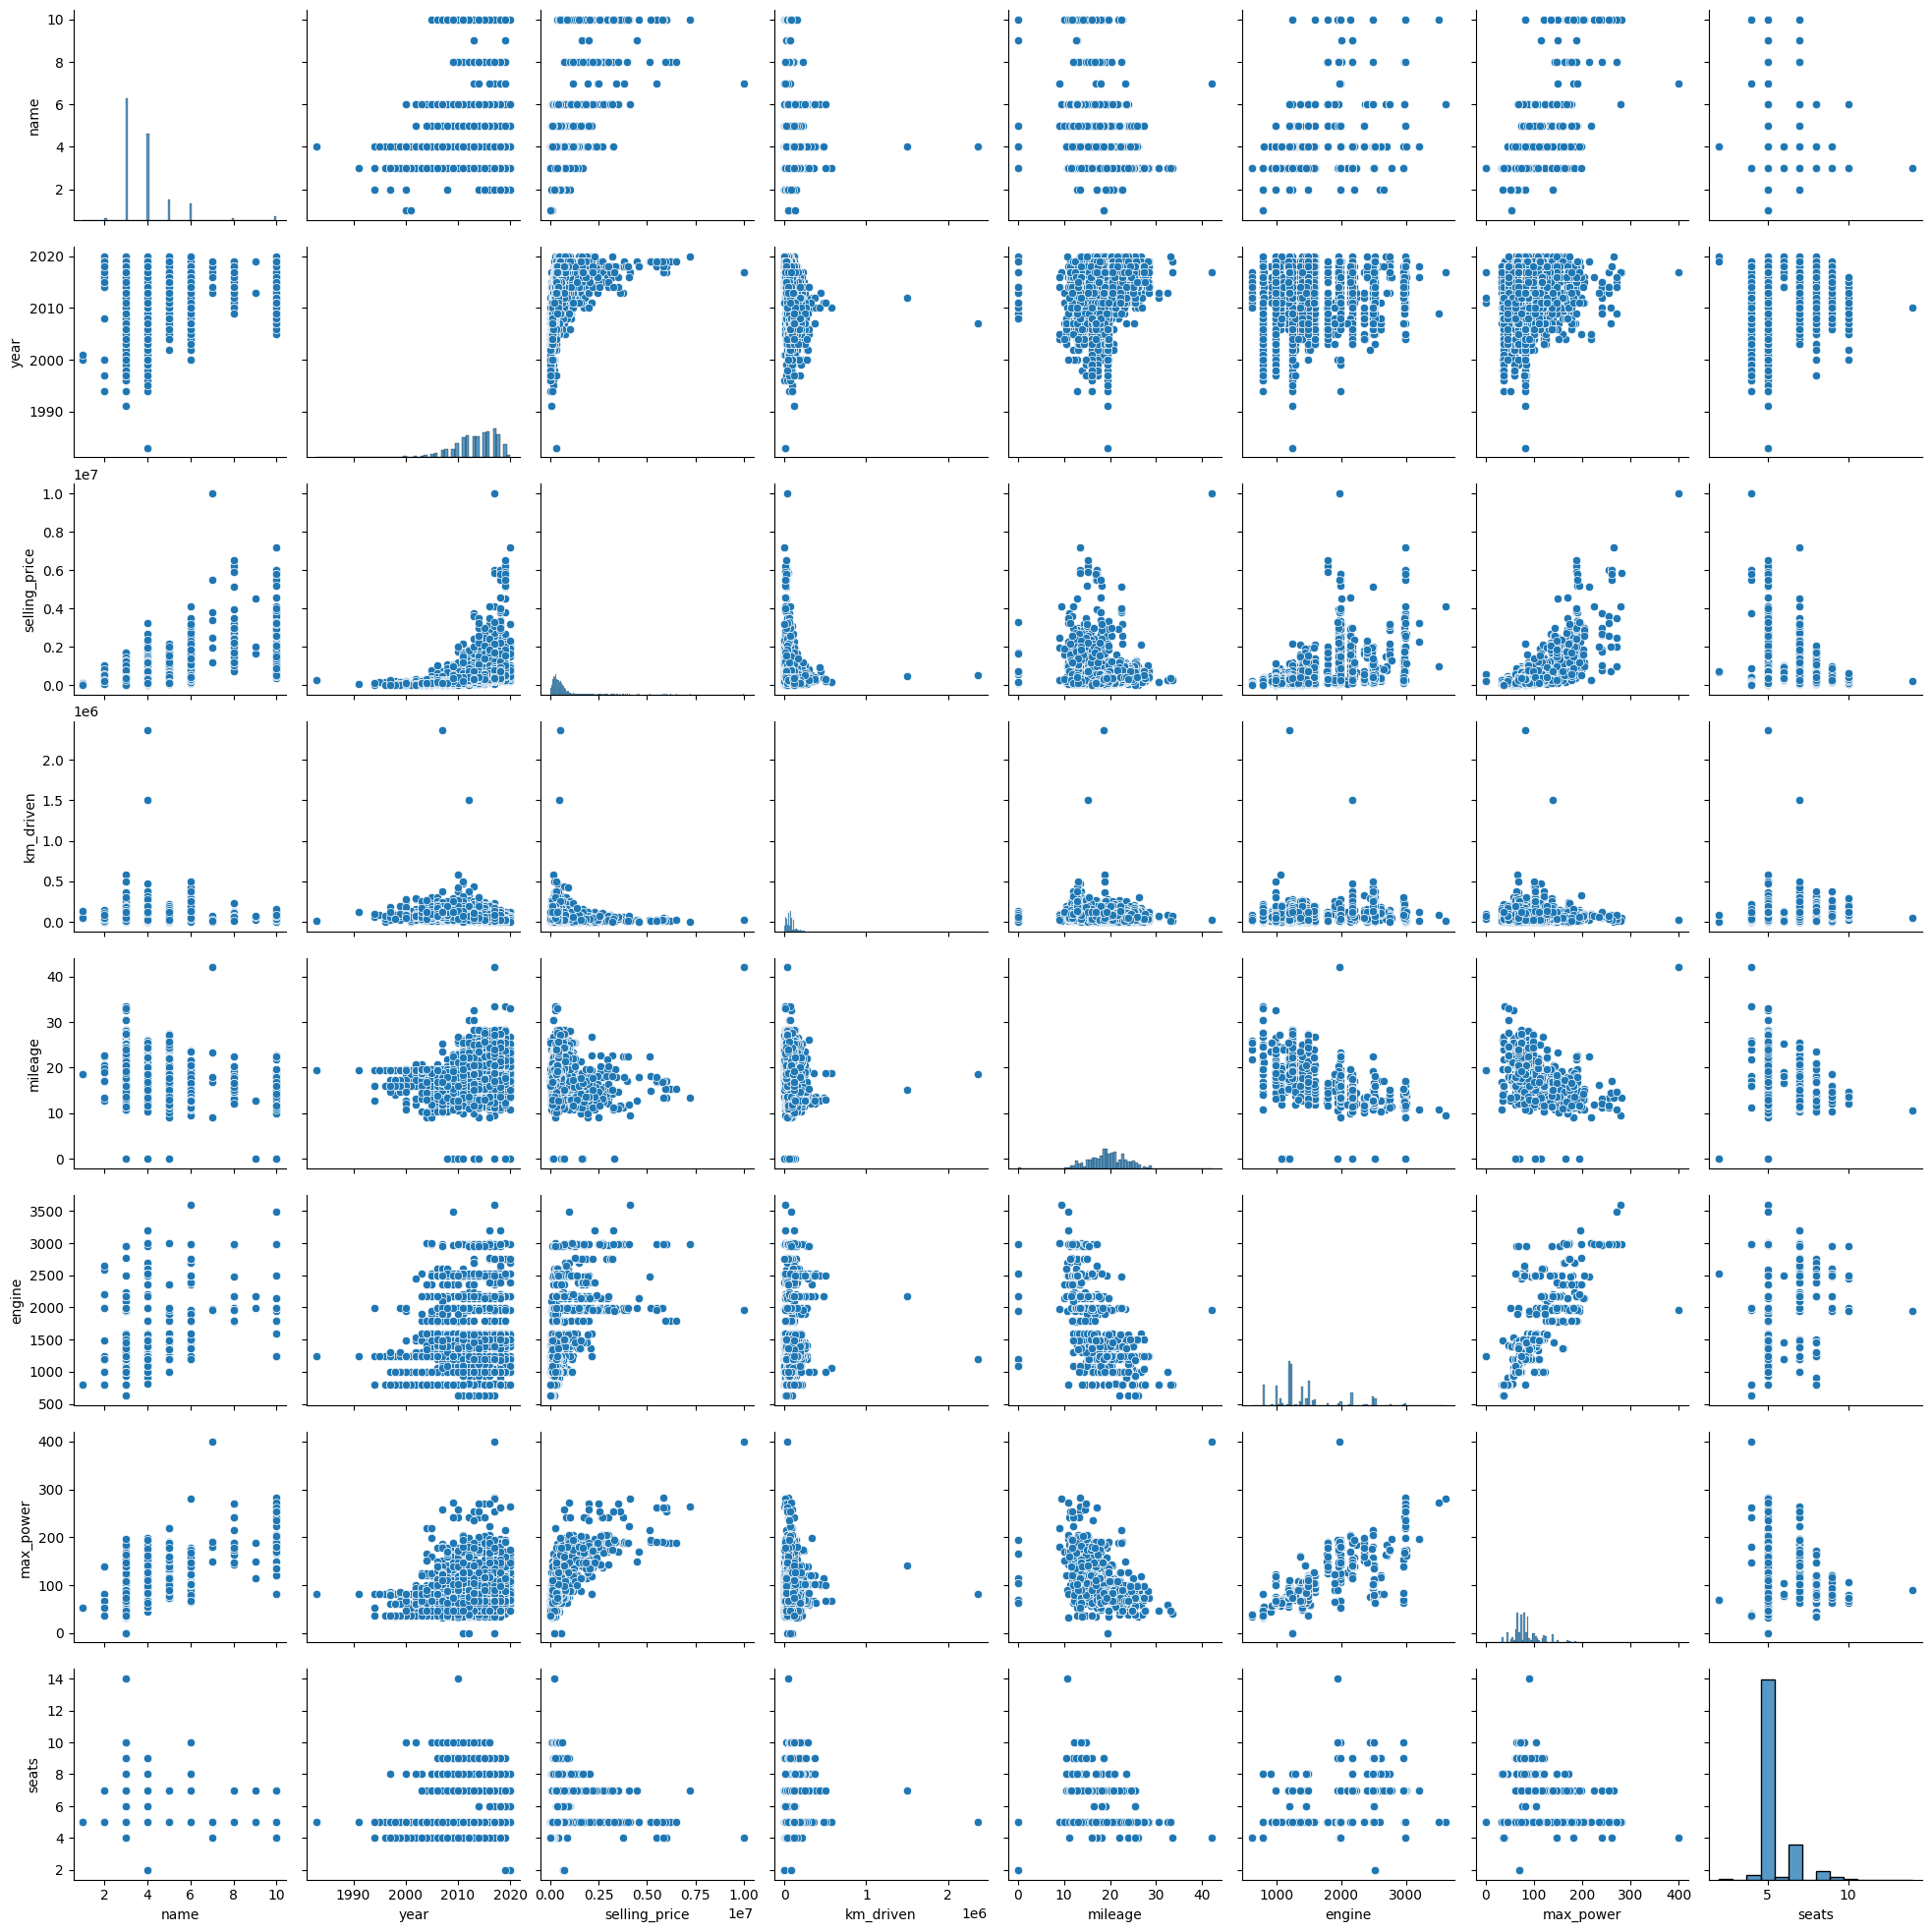

In [89]:
import seaborn as sb
%matplotlib inline
sb.pairplot(df_train)

На оба вопроса - ответ "Да". Например явно видно что положительная корреляция у таргета есть с годом (деньги обесцениваются и машины начинают стоить дороже) и с макс пауэр (чем мощнее машина тем дороже). Еще пример выраженной корреляции - engine и max_power

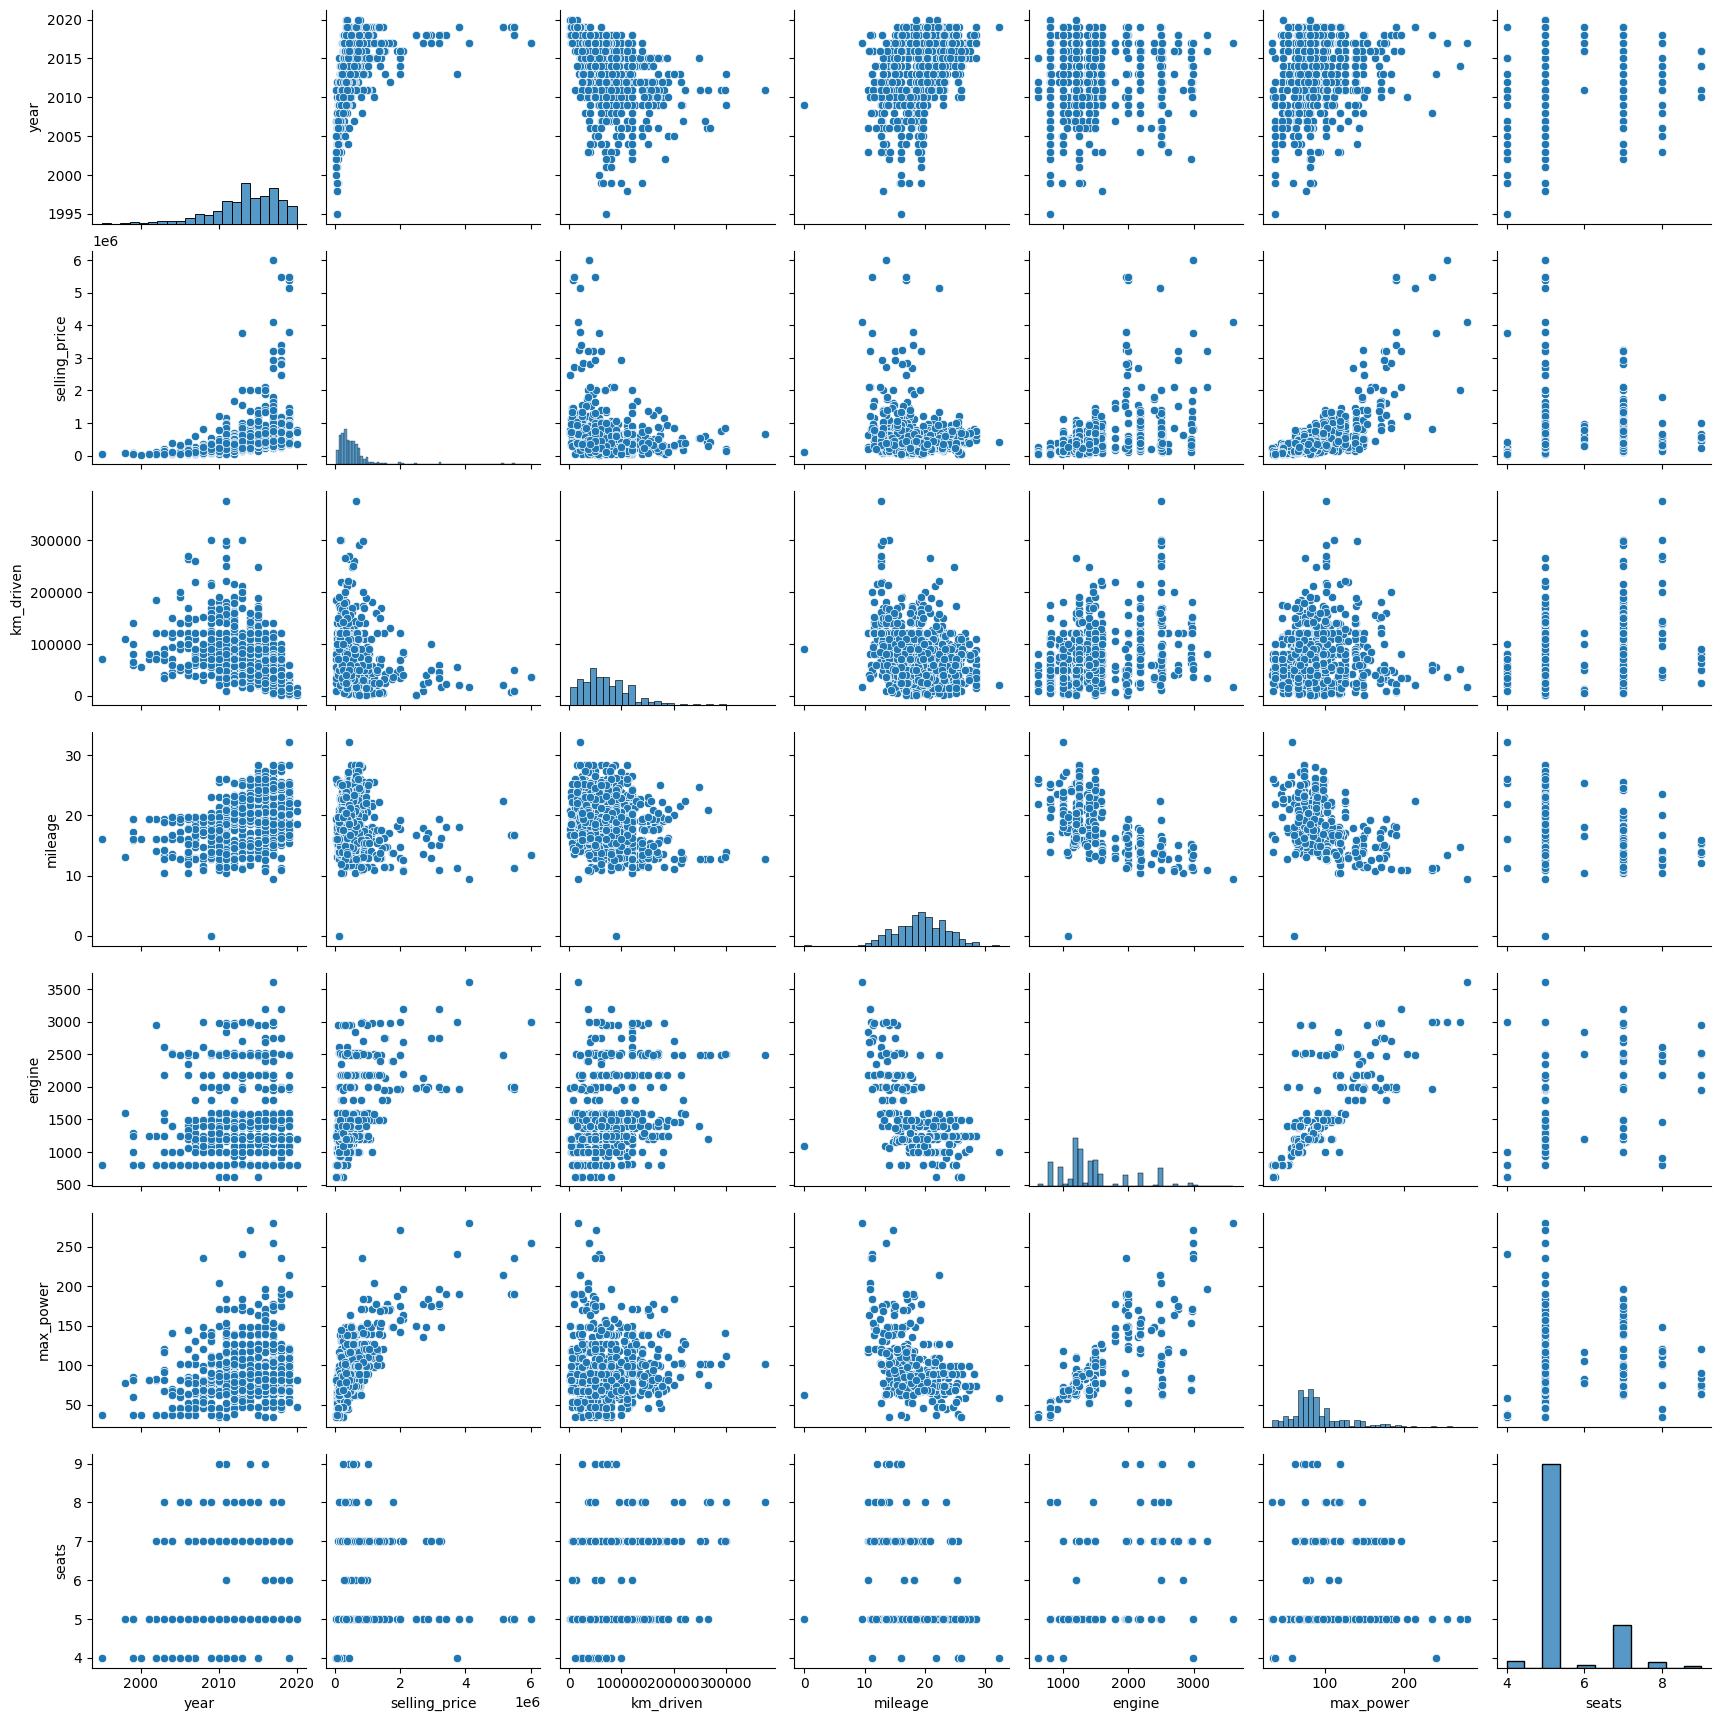

In [31]:
sb.pairplot(df_test)

**Похожими ли оказались совокупности при разделении на трейн и тест?**

Оказались похожими :)

Не могу сказать что каждую пару посмотрел, но по таргету точно похоже, однако судя по гистам на диагонали трейна - там есть турбо-выбросы

### **Задание 7 (0.35 балла)**

Итак, вы выдвинули гипотезы о наличии связи. Теперь давайте оценим эту связь в числах.

**Задание:**
- [X] Получите значения коэффициента корреляции Пирсона для тренировочного набора данных при помощи `DataFrame.corr()`
- [X] По полученным корреляциям постройте тепловую карту (`heatmap` из библиотеки seaborn)

In [32]:
df_train.corr(numeric_only=True)

,year,selling_price,km_driven,mileage,engine,max_power,seats
year,1.000000,0.427279,-0.368966,0.341334,0.002819,0.156858,0.041178
selling_price,0.427279,1.000000,-0.164828,-0.104769,0.447672,0.692814,0.149953
km_driven,-0.368966,-0.164828,1.000000,-0.182086,0.229766,0.024588,0.192328
mileage,0.341334,-0.104769,-0.182086,1.000000,-0.572893,-0.373390,-0.451059
engine,0.002819,0.447672,0.229766,-0.572893,1.000000,0.681117,0.652172
max_power,0.156858,0.692814,0.024588,-0.373390,0.681117,1.000000,0.244112
seats,0.041178,0.149953,0.192328,-0.451059,0.652172,0.244112,1.000000


<Axes: >

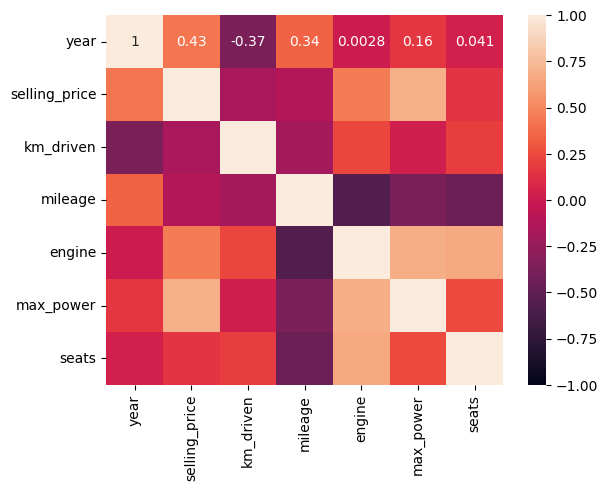

In [33]:
sb.heatmap(df_train.corr(numeric_only=True), vmin=-1, vmax=1, annot=True)

- [X] Ответьте на вопросы:
 - Какие 2 признака наименее скоррелированы между собой?
 - Между какими наблюдается довольно сильная положительная линейная зависимость?
 - Правильно ли, опираясь на данные, утверждать, что чем меньше год, тем, скорее всего, больше километров проехала машина к дате продажи?

1. Год и engine
2. Как и писал раньше max power & engine, max power & sp, engine & sp. Помимо этого engine & seats
3. Правильно

### **Задание 8 (0.25 балла)**

Если вам кажется, что мы не попросили вас нарисовать какие-то очень важные зависимости, нарисуйте их **и поясните.**

- [X] Постройте хотя бы одну дополнительную визуализацию и объясните, что она показывает и почему это важно.

In [34]:
#Давайте марки машин посмотрим
df_train.name.apply(lambda x: x.split()[0]).value_counts()

name
Maruti           1804
Hyundai          1058
Mahindra          611
Tata              534
Toyota            309
Ford              308
Honda             308
Chevrolet         188
Renault           171
Volkswagen        153
Nissan             63
Skoda              61
Datsun             49
Mercedes-Benz      44
BMW                41
Fiat               39
Audi               31
Jeep               20
Mitsubishi          8
Volvo               8
Jaguar              7
Force               4
Isuzu               4
Land                3
MG                  3
Daewoo              3
Kia                 3
Ambassador          3
Lexus               1
Peugeot             1
Name: count, dtype: int64

<Axes: xlabel='name', ylabel='selling_price'>

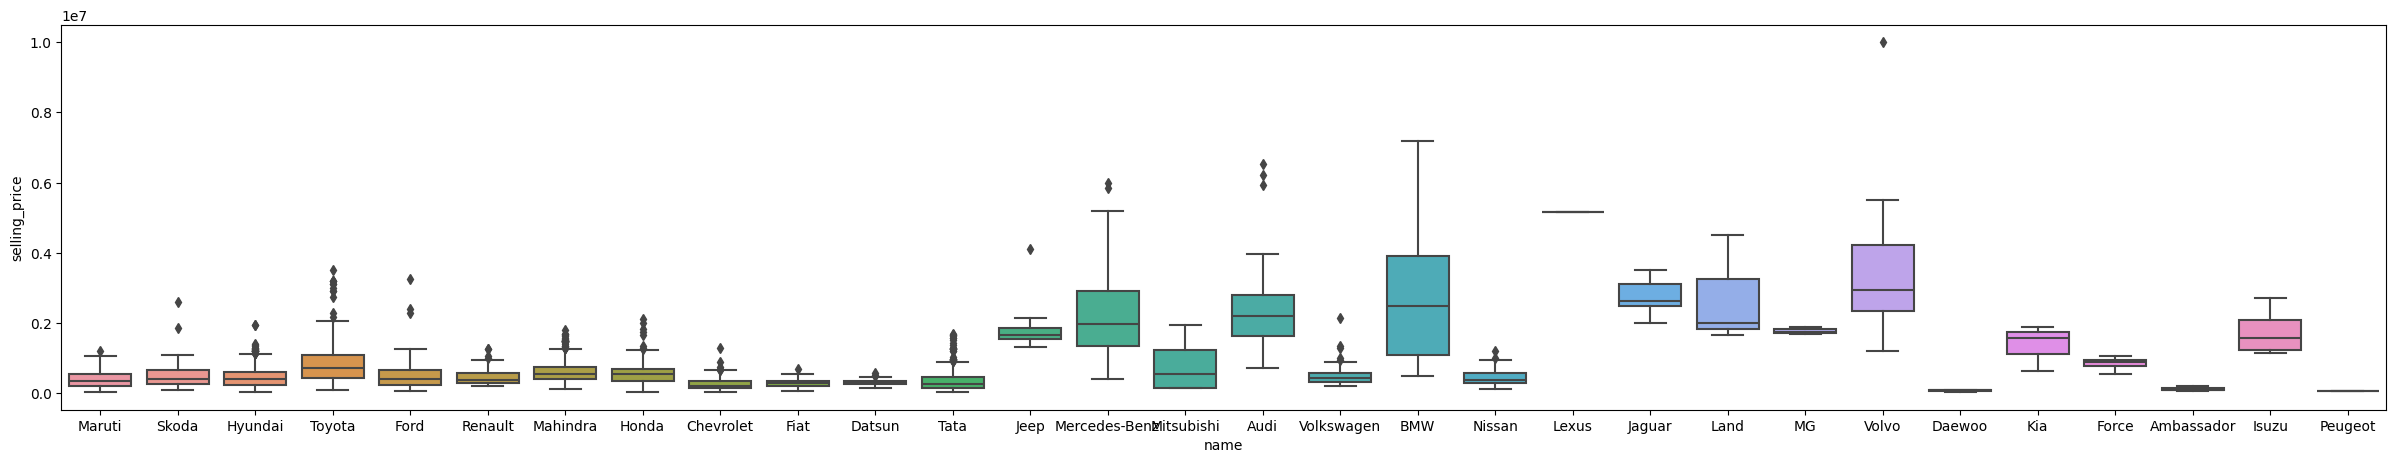

In [35]:
plt.figure(figsize=(30, 5))
sb.boxplot(df_train, x=df_train.name.apply(lambda x: x.split()[0]), y='selling_price')

Марка как будто важная фича для цены (престиж, все дела) и график это подтверждает

# **Часть 2 | Модель только на вещественных признаках**

В этой части вам предстоит обучить модель только на вещественных признаках. Почему только на них?

Чем больше признаковое пространство — тем сложнее модель. А чем модель проще — тем лучше для скорости работы и интерпретации признаков.

За задания этой части вы можете набрать 1.25 балла.

### **Задание 9 (0.05 балла)**

Сделайте тренировочный и тестовый наборы. Они уже даны, достаточно просто отделить целевой признак. Перед разбиением создайте копию датафрейма, который будет хранить только вещественные признаки и используйте его (то есть категориальные столбцы (все, кроме seats) необходимо удалить).

В переменные y_train и y_test запишите значения целевых переменных. Используйте уже имеющиеся данные train и test при разбиении. Если считаете уместным применить какую-то более хитрую технику разбиения — примените, но опишите, зачем.

In [36]:
df_train

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248,74.00,5
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498,103.52,5
2,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396,90.00,5
3,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298,88.20,5
4,Hyundai Xcent 1.2 VTVT E Plus,2017,440000,45000,Petrol,Individual,Manual,First Owner,20.14,1197,81.86,5
...,...,...,...,...,...,...,...,...,...,...,...,...
5835,Hyundai Santro Xing GLS,2008,120000,191000,Petrol,Individual,Manual,First Owner,17.92,1086,62.10,5
5836,Maruti Wagon R VXI BS IV with ABS,2013,260000,50000,Petrol,Individual,Manual,Second Owner,18.90,998,67.10,5
5837,Hyundai i20 Magna,2013,320000,110000,Petrol,Individual,Manual,First Owner,18.50,1197,82.85,5
5838,Hyundai Verna CRDi SX,2007,135000,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.80,1493,110.00,5


In [37]:
y_train = df_train.selling_price.copy()
X_train = df_train[['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']].copy()

In [38]:
y_test = df_test.selling_price.copy()
X_test = df_test[['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']].copy()

### **Задание 10 (0.2 балла)**

Построим нашу первую модель!
- [X] Обучите классическую линейную регрессию с дефолтными параметрами. Посчитайте $R^2$ и $MSE$ для трейна и для теста.
- [X] Сделайте выводы по значениям метрик качества.

**Примечание:**

Здесь и далее $R^2$ и $MSE$ для трейна и для теста выводите везде, где требуется обучать модели, даже если в явном виде этого не просят. Иначе непонятно, как понять, насколько успешны наши эксперименты.

In [39]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score

r = LinearRegression().fit(X_train, y_train)
pred = r.predict(X_test)
pred_train = r.predict(X_train)

In [40]:
print(f'MSE тест: {mean_squared_error(y_test, pred):.3f}  MSE трейн: {mean_squared_error(y_train, pred_train):.3f}')
print(f'RMSE тест: {np.sqrt(mean_squared_error(y_test, pred)):.3f}  RMSE трейн: {np.sqrt(mean_squared_error(y_train, pred_train)):.3f}')
print(f'R2 тест: {r2_score(y_test, pred):.3f}  R2 трейн: {r2_score(y_train, pred_train):.3f}')

MSE тест: 233298779730.459  MSE трейн: 116874153930.029
RMSE тест: 483010.124  RMSE трейн: 341868.621
R2 тест: 0.594  R2 трейн: 0.592


По MSE естественно ничего не понятно, потому что это квадраты больших денег, R2 же подсказывает что все работает не так уж плохо (общие закономерности улавляиваются и половину дисперссии мы как-то объясняем), более того качество на тесте немного выше чем на трейне - значит мы скорее всего не переобучились. 

При этом RMSE все равно жуткий, ошибаться на 300к при продаже - не ок. Скорее всего дело в выбросах в таргете

### **Задание 11 (0.15 балла)**

Всегда есть место совершенству. Поэтому давайте попробуем улучшить модель при помощи стандартизации признаков.

- [X] Стандартизируйте значения в тренировочных и тестовых данных. Стандартизатор **обучайте только на `train`**.

In [41]:
from sklearn.preprocessing import StandardScaler

ss = StandardScaler().fit(X=X_train)
X_train_preproc = ss.transform(X_train)
X_test_preproc = ss.transform(X_test)

In [42]:
r_n = LinearRegression().fit(X_train_preproc, y_train)
pred_n = r_n.predict(X_test_preproc)
pred_train_n = r_n.predict(X_train_preproc)

In [43]:
print(f'MSE тест: {mean_squared_error(y_test, pred_n):.3f}  MSE трейн: {mean_squared_error(y_train, pred_train_n):.3f}')
print(f'RMSE тест: {np.sqrt(mean_squared_error(y_test, pred_n)):.3f}  RMSE трейн: {np.sqrt(mean_squared_error(y_train, pred_train_n)):.3f}')
print(f'R2 тест: {r2_score(y_test, pred_n):.3f}  R2 трейн: {r2_score(y_train, pred_train_n):.3f}')

MSE тест: 233298779730.450  MSE трейн: 116874153930.029
RMSE тест: 483010.124  RMSE трейн: 341868.621
R2 тест: 0.594  R2 трейн: 0.592


### **Задание 12 (0.1 балла)**

Хотя стандартизация не помогла сильно прибавить в качестве, она открыла возможность интерпретировать важность признаков в модели. Правило интерпретации такое:

Чем больше коэффициент $\beta_i$ по модулю, тем важнее признак.

**Ответьте на вопрос:**

- [X] Какой признак оказался наиболее информативным в предсказании цены?

In [44]:
for column, value in zip(X_train.columns, r_n.coef_):
    print(column, abs(value))

year 152772.57084581678
km_driven 44158.81852005294
mileage 28833.925777517
engine 61178.49433684783
max_power 322807.35325923306
seats 23209.13248599717


Max_power оказался самым важным

### **Задание 13 (0.25 балла)**

Попробуем улучшить нашу модель с помощью применения регуляризации. Для этого воспользуемся `Lasso` регрессией.  Кроме того, попробуйте использовать её теоретическое свойство отбора признаков, за счет зануления незначимых коэффициентов.

**Задание:**

- [X] Обучите Lasso регрессию на тренировочном наборе данных со стандартизованными признаками. Оцените её качество
- [X] Проверьте, занулила ли L1-регуляризация с параметрами по умолчанию какие-нибудь веса? Предположите почему.

In [45]:
from sklearn.linear_model import Lasso

In [46]:
l = Lasso().fit(X_train_preproc, y_train)
pred_l = l.predict(X_test_preproc)
pred_train_l = l.predict(X_train_preproc)

In [47]:
print(f'MSE тест: {mean_squared_error(y_test, pred_l):.3f}  MSE трейн: {mean_squared_error(y_train, pred_train_l):.3f}')
print(f'RMSE тест: {np.sqrt(mean_squared_error(y_test, pred_l)):.3f}  RMSE трейн: {np.sqrt(mean_squared_error(y_train, pred_train_l)):.3f}')
print(f'R2 тест: {r2_score(y_test, pred_l):.3f}  R2 трейн: {r2_score(y_train, pred_train_l):.3f}')

MSE тест: 233299450599.169  MSE трейн: 116874153940.143
RMSE тест: 483010.818  RMSE трейн: 341868.621
R2 тест: 0.594  R2 трейн: 0.592


In [48]:
for column, value in zip(X_train.columns, l.coef_):
    print(column, abs(value))

year 152772.39021419577
km_driven 44157.68985794259
mileage 28832.043395883888
engine 61173.66240922139
max_power 322808.2369194693
seats 23206.255649080187


Не занулила, вероятно из-за огромных значений и небольшого значения гиперпараметра.

### **Задание 14 Финальный рывок (0.5 балла)**

До этого мы с вами использовали `train` для обучения и `test` для прогнозирования. Но у нас есть ещё одна задача — подобрать оптимальные параметры модели. Для этого используем кросс-валидацию, описанную на семинарах.

Кроме того, выжмем максимум из модификаций регрессии. Построим `ElasticNet`. И сделаем всё по порядку.

**Ваша задача 1:**

- [X] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для Lasso-регрессии. Вам пригодится класс [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
- [X] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Какой коэффициент регуляризации у лучшей из перебранных моделей? Занулились ли какие-нибудь из весов при такой регуляризации?

In [49]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import ElasticNet

In [50]:
parameters = {'alpha':[1/10**i for i in range(-6, 6)] + [0]}

In [51]:
gsl = GridSearchCV(Lasso(), param_grid=parameters, verbose=True, cv=10, scoring='r2')
gsl.fit(X_train_preproc, y_train)

Fitting 10 folds for each of 13 candidates, totalling 130 fits


GridSearchCV(cv=10, estimator=Lasso(),
             param_grid={'alpha': [1000000.0, 99999.99999999999, 10000.0,
                                   1000.0, 100.0, 10.0, 1.0, 0.1, 0.01, 0.001,
                                   0.0001, 1e-05, 0]},
             scoring='r2', verbose=True)

In [52]:
gsl.best_params_, gsl.best_score_

({'alpha': 10000.0}, 0.5727197315544514)

In [53]:
for column, value in zip(X_train.columns, gsl.best_estimator_.coef_):
    print(column, abs(value))

year 151810.98386365655
km_driven 32735.11356628637
mileage 9285.997922053115
engine 17841.622334842235
max_power 329230.1475717452
seats 0.0


In [54]:
pred_gsl = gsl.best_estimator_.predict(X_test_preproc)
pred_train_gsl = gsl.best_estimator_.predict(X_train_preproc)

In [55]:
print(f'MSE тест: {mean_squared_error(y_test, pred_gsl):.3f}  MSE трейн: {mean_squared_error(y_train, pred_train_gsl):.3f}')
print(f'RMSE тест: {np.sqrt(mean_squared_error(y_test, pred_gsl)):.3f}  RMSE трейн: {np.sqrt(mean_squared_error(y_train, pred_train_gsl)):.3f}')
print(f'R2 тест: {r2_score(y_test, pred_gsl):.3f}  R2 трейн: {r2_score(y_train, pred_train_gsl):.3f}')

MSE тест: 240511826990.226  MSE трейн: 117736595208.784
RMSE тест: 490420.052  RMSE трейн: 343127.666
R2 тест: 0.582  R2 трейн: 0.589


**Сколько грид-сёрчу пришлось обучать моделей?**

130


**Какой коэффициент регуляризации у лучшей из перебранных моделей? Занулились ли какие-нибудь из весов при такой регуляризации?**

10k, занулился seats


Но метрики стали хуже

**Ваша задача 2:**

- [X] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для [ElasticNet](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html) регрессии.
- [x] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Какие гиперпараметры соответствуют лучшей (по выбранной метрике качества) из перебранных моделей?

In [56]:
parameters = {'alpha':[1/10**i for i in range(-6, 6)] + [0], 'l1_ratio':[i/10 for i in range(10)]}

In [57]:
gsen = GridSearchCV(ElasticNet(), param_grid=parameters, verbose=True, cv=10, scoring='r2')
gsen.fit(X_train_preproc, y_train)

Fitting 10 folds for each of 130 candidates, totalling 1300 fits


GridSearchCV(cv=10, estimator=ElasticNet(),
             param_grid={'alpha': [1000000.0, 99999.99999999999, 10000.0,
                                   1000.0, 100.0, 10.0, 1.0, 0.1, 0.01, 0.001,
                                   0.0001, 1e-05, 0],
                         'l1_ratio': [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7,
                                      0.8, 0.9]},
             scoring='r2', verbose=True)

In [58]:
gsen.best_params_, gsen.best_score_

({'alpha': 1.0, 'l1_ratio': 0.9}, 0.5761314666976898)

In [59]:
for column, value in zip(X_train.columns, gsen.best_estimator_.coef_):
    print(column, abs(value))

year 145991.7076021064
km_driven 46026.44130357313
mileage 22873.49724580271
engine 79236.68054915406
max_power 281553.75282181124
seats 24513.52612258027


In [60]:
pred_gsen = gsen.best_estimator_.predict(X_test_preproc)
pred_train_gsen = gsen.best_estimator_.predict(X_train_preproc)

In [61]:
print(f'MSE тест: {mean_squared_error(y_test, pred_gsen):.3f}  MSE трейн: {mean_squared_error(y_train, pred_train_gsen):.3f}')
print(f'RMSE тест: {np.sqrt(mean_squared_error(y_test, pred_gsen)):.3f}  RMSE трейн: {np.sqrt(mean_squared_error(y_train, pred_train_gsen)):.3f}')
print(f'R2 тест: {r2_score(y_test, pred_gsen):.3f}  R2 трейн: {r2_score(y_train, pred_train_gsen):.3f}')

MSE тест: 245894595583.237  MSE трейн: 117993441993.759
RMSE тест: 495877.601  RMSE трейн: 343501.735
R2 тест: 0.572  R2 трейн: 0.588


**Сколько грид-сёрчу пришлось обучать моделей?**

1300


**Какие гиперпараметры соответствуют лучшей (по выбранной метрике качества) из перебранных моделей?**

{'alpha': 1.0, 'l1_ratio': 0.9}


Но метрики стали **ЕЩЕ** хуже

# **Часть 3 | Добавляем категориальные фичи**

Попробуем для улучшения модели дать ей больше признаков. Добавим категориальные фичи.

За эту часть можно набрать 0.75 балла.

**Задание 15 (0.1 балла)** Проанализируйте столбец `name`. Очевидно, что эта переменная является категориальной, однако категорий в ней много.

В этом домашнем задании мы предлагаем удалить его.

**Ваша задача:**
- [X] Создайте `X_train_cat` и `X_test_cat` — копии `df_train` и `df_test` без целевой переменной (со всеми признаками, включая категориальные)
- [X] Удалите из них столбец `name`

**Давайте оставим**

На name я уже смотрел выше и хочу его оставить. Можно было бы счетчики посчиать по топ маркам + мелкие завернуть в "прочее"

Но попробуем иначе - я попросил клода проставить балл престижности для каждой из этих марок - с рейтингами можно работать по-разному, попробуем как с вещественной фичой

In [62]:
df_train.name = df_train.name.apply(lambda x: x.split()[0])
df_test.name = df_test.name.apply(lambda x: x.split()[0])

In [63]:
prestige = {
    # люкс
    'Mercedes-Benz': 10, 'BMW': 10,
    'Land': 9,
    'Audi': 8, 'Jaguar': 8, 'Lexus': 8,
    'Volvo': 7,
    # верх массового рынка
    'Jeep': 6, 'Toyota': 6, 'Skoda': 6,
    'Honda': 5, 'Volkswagen': 5, 'Kia': 5, 'MG': 5,
    # массовый сегмент
    'Hyundai': 4, 'Mahindra': 4, 'Ford': 4, 'Mitsubishi': 4, 'Isuzu': 4,
    'Maruti': 3, 'Tata': 3, 'Renault': 3, 'Nissan': 3, 'Chevrolet': 3, 'Fiat': 3,
    # бюджетные
    'Datsun': 2, 'Force': 2, 'Ambassador': 2, 'Peugeot': 2,
    'Daewoo': 1,
}

In [64]:
df_train.name = df_train.name.map(prestige)

In [65]:
df_train.name.median()

4.0

In [66]:
#В тесте при этом есть две новые марки, в реальной жизни мы бы заменяли бы неизвестное на дефолтное - 4 (медиана трейна)
df_test[df_test.name.map(prestige).isna()]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats
544,Opel,1998,68000,110000,Petrol,Individual,Manual,Third Owner,13.10,1598,77.0,5
856,Ashok,2013,300000,200000,Diesel,Individual,Manual,Second Owner,20.07,1461,75.0,8


In [67]:
df_test.name = df_test.name.map(prestige)

In [68]:
df_test.name.fillna(4, inplace=True)

~~В другом случае, конечно, мы могли бы предобработать данный столбец (например, выделить из названия марку автомобиля). В этом задании этого делать не нужно.~~

In [69]:
cat_f = ['fuel', 'seller_type', 'transmission', 'owner', 'seats']
num_f = ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'name']

In [70]:
new_num_X_train = df_train[num_f].copy()
new_num_X_test = df_test[num_f].copy()

In [71]:
ss = StandardScaler().fit(new_num_X_train)
new_num_X_train_norm = pd.DataFrame(ss.transform(new_num_X_train), columns=num_f)
new_num_X_test_norm = pd.DataFrame(ss.transform(new_num_X_test), columns=num_f)

In [72]:
X_train_cat = pd.concat([new_num_X_train_norm, df_train[cat_f]], axis=1).copy()
X_test_cat = pd.concat([new_num_X_test_norm, df_test[cat_f]], axis=1).copy()

In [73]:
# Проверку заменил, кол-во фичей теперь 11 а не 10
assert X_train_cat.shape == (5840, 11)

In [74]:
X_train_cat.describe(include='object')

,fuel,seller_type,transmission,owner
count,5840,5840,5840,5840
unique,4,3,2,5
top,Diesel,Individual,Manual,First Owner
freq,3177,5223,5336,3603


### **Задание 16 (0.4 балла)**

- [X] Закодируйте категориальные фичи и ``seats`` методом OneHot-кодирования. Обратите внимание, что во избежание мультиколлинеарности следует избавиться от одного из полученных столбцов при кодировании каждого признака методом OneHot.

In [75]:
from sklearn.preprocessing import OneHotEncoder

In [76]:
ohe=OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore').fit(X_train_cat[cat_f])
dummy_train = pd.DataFrame(ohe.transform(X_train_cat[cat_f]), columns=ohe.get_feature_names_out())
dummy_test = pd.DataFrame(ohe.transform(X_test_cat[cat_f]), columns=ohe.get_feature_names_out())
X_train_cat = pd.concat([X_train_cat, dummy_train], axis=1)
X_test_cat = pd.concat([X_test_cat, dummy_test], axis=1)
X_train_cat.drop(columns=cat_f, inplace=True)
X_test_cat.drop(columns=cat_f, inplace=True)

### **Задание 17 (0.25 балла)**
Повторим то, что делали на прошлом шаге для моделей на вещественных признаках, однако теперь с моделью `Ridge`.


**Ваша задача:**
- [X] Переберите параметр регуляризации `alpha` для гребневой (ridge) регрессии с помощью класса `GridSearchCV`. В качестве параметров при объявлении GridSearchCV кроме модели укажите метрику качества $R^2$. Кроссвалидируйтесь по 10-ти фолдам.
- [X] Ответьте на вопрос: Удалось ли улучшить качество прогнозов?

In [77]:
parameters = {'alpha':[1/10**i for i in range(-6, 6)] + [0]}
gsr = GridSearchCV(Ridge(), param_grid=parameters, verbose=True, cv=10, scoring='r2')
gsr.fit(X_train_cat, y_train)

Fitting 10 folds for each of 13 candidates, totalling 130 fits


GridSearchCV(cv=10, estimator=Ridge(),
             param_grid={'alpha': [1000000.0, 99999.99999999999, 10000.0,
                                   1000.0, 100.0, 10.0, 1.0, 0.1, 0.01, 0.001,
                                   0.0001, 1e-05, 0]},
             scoring='r2', verbose=True)

In [78]:
gsr.best_params_, gsr.best_score_

({'alpha': 10.0}, 0.6534874449528255)

In [79]:
for column, value in zip(X_train_cat.columns, gsr.best_estimator_.coef_):
    print(column, abs(value))

year 146790.36965450196
km_driven 33269.27385375423
mileage 41446.02524001052
engine 10222.990797308565
max_power 241506.35736223863
name 138418.56872600853
fuel_Diesel 18525.867840835424
fuel_LPG 106121.55203155988
fuel_Petrol 38712.35135836952
seller_type_Individual 78660.19407165848
seller_type_Trustmark Dealer 93929.52479609931
transmission_Manual 213027.56193927533
owner_Fourth & Above Owner 31579.0382909912
owner_Second Owner 58048.165410088375
owner_Test Drive Car 908506.2872101325
owner_Third Owner 35543.126507676076
seats_4 363522.83728174656
seats_5 144405.7020968376
seats_6 194161.4709341336
seats_7 36981.83323259247
seats_8 70003.44410075109
seats_9 4731.791519858229
seats_10 59295.5736351515
seats_14 12117.94040659799


In [80]:
pred_gsr = gsr.best_estimator_.predict(X_test_cat)
pred_train_gsr = gsr.best_estimator_.predict(X_train_cat)

In [81]:
print(f'MSE тест: {mean_squared_error(y_test, pred_gsr):.3f}  MSE трейн: {mean_squared_error(y_train, pred_train_gsr):.3f}')
print(f'RMSE тест: {np.sqrt(mean_squared_error(y_test, pred_gsr)):.3f}  RMSE трейн: {np.sqrt(mean_squared_error(y_train, pred_train_gsr)):.3f}')
print(f'R2 тест: {r2_score(y_test, pred_gsr):.3f}  R2 трейн: {r2_score(y_train, pred_train_gsr):.3f}')

MSE тест: 178176963134.726  MSE трейн: 89028701424.163
RMSE тест: 422110.132  RMSE трейн: 298376.778
R2 тест: 0.690  R2 трейн: 0.689


In [82]:
from sklearn.metrics import mean_absolute_error
print(f'MAE тест: {mean_absolute_error(y_test, pred_gsr):.3f}  MAE трейн: {mean_absolute_error(y_train, pred_train_gsr):.3f}')

MAE тест: 206858.328  MAE трейн: 169943.668


**Ответьте на вопрос: Удалось ли улучшить качество прогнозов?**

Удалось, улучшились все метрики на тесте. Ниже попробовал без name (дал ли он прирост)

In [83]:
parameters = {'alpha':[1/10**i for i in range(-6, 6)] + [0]}
gsr_wo = GridSearchCV(Ridge(), param_grid=parameters, verbose=True, cv=10, scoring='r2')
gsr_wo.fit(X_train_cat.drop(columns='name'), y_train)

Fitting 10 folds for each of 13 candidates, totalling 130 fits


GridSearchCV(cv=10, estimator=Ridge(),
             param_grid={'alpha': [1000000.0, 99999.99999999999, 10000.0,
                                   1000.0, 100.0, 10.0, 1.0, 0.1, 0.01, 0.001,
                                   0.0001, 1e-05, 0]},
             scoring='r2', verbose=True)

In [84]:
gsr_wo.best_params_, gsr_wo.best_score_

({'alpha': 10.0}, 0.6220694732316957)

In [85]:
pred_gsr_wo = gsr_wo.best_estimator_.predict(X_test_cat.drop(columns='name'))
pred_train_gsr_wo = gsr_wo.best_estimator_.predict(X_train_cat.drop(columns='name'))

In [86]:
print(f'MSE тест: {mean_squared_error(y_test, pred_gsr_wo):.3f}  MSE трейн: {mean_squared_error(y_train, pred_train_gsr_wo):.3f}')
print(f'RMSE тест: {np.sqrt(mean_squared_error(y_test, pred_gsr_wo)):.3f}  RMSE трейн: {np.sqrt(mean_squared_error(y_train, pred_train_gsr_wo)):.3f}')
print(f'R2 тест: {r2_score(y_test, pred_gsr_wo):.3f}  R2 трейн: {r2_score(y_train, pred_train_gsr_wo):.3f}')

MSE тест: 203804808290.192  MSE трейн: 99238428030.943
RMSE тест: 451447.459  RMSE трейн: 315021.314
R2 тест: 0.645  R2 трейн: 0.654


name дал ощутимый прирост,но результат с категориальными но без name все равно лучше всего что было до этого

# **Часть 4 | Бизнесовая (0.5 балла)**

### **Задание 18 (0.5 балла)**

В мире бизнеса очень важно давать оценку качества модели понятную бизнесу, поэтому иногда заказчики приходят с кастомными метриками. Попробуем сделать такую для нашей задачи.

**Описание метрики:**

Среди всех предсказанных цен на авто нужно посчитать долю прогнозов, отличающихся от реальных цен на эти авто не более чем на 10% (в одну или другую сторону). Отклонение считается относительно **реальной** цены $y_i$:

$$\text{business\_metric}(y, \hat y) = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\left[\frac{|\hat y_i - y_i|}{y_i} \le 0.1\right]$$

**Ваша задача:**

- [X] Реализуйте метрику `business_metric`
- [X] Посчитайте метрику для всех обученных моделей и определите, какая лучше всего решает задачу бизнеса

In [87]:
def business_metric(y_true, y_pred):
   return (((abs(y_true-y_pred)/y_true) <= 0.1).sum())/y_true.shape[0]

print(f'Базовая LR, исходные числовые признаки: {business_metric(y_test, pred)}')
print(f'Базовая LR + стандартизация, исходные числовые признаки: {business_metric(y_test, pred_n)}')
print(f'Lasso a=1 + стандартизация, без категориальных: {business_metric(y_test, pred_l)}')
print(f'GS Lasso a=10k + стандартизация, без категориальных: {business_metric(y_test, pred_gsl)}')
print(f'GS ElasticNet, a=1, доля L1=0,9 + стандартизация, без категориальных: {business_metric(y_test, pred_gsen)}')
print(f'Ridge, категории без рейтинга марки, a=10: {business_metric(y_test, pred_gsr_wo)}')
print(f'Ridge, категории с рейтингом марки, a=10: {business_metric(y_test, pred_gsr)}')

Базовая LR, исходные числовые признаки: 0.227
Базовая LR + стандартизация, исходные числовые признаки: 0.227
Lasso a=1 + стандартизация, без категориальных: 0.227
GS Lasso a=10k + стандартизация, без категориальных: 0.235
GS ElasticNet, a=1, доля L1=0,9 + стандартизация, без категориальных: 0.241
Ridge, категории без рейтинга марки, a=10: 0.248
Ridge, категории с рейтингом марки, a=10: 0.206


Лучше всего решает задачу Ridge без рейтинга марки - SAD

# **Часть 5 | Оформление репозитория (2 балла)**

Домашнее задание оформите как репозиторий на GitHub.

---

### Обязательные файлы:

1. **`.ipynb`-ноутбук** со всеми экспериментами (0.5 балла):

   * полный EDA,
   * все шаги препроцессинга,
   * обучение и сравнение моделей,
   * сохранённые output’ы;
   * ноутбук запускается сверху вниз без ошибок.

2. **`.pickle`-файл** (0.5 балла), содержащий:

   * обученную модель (или пайплайн `scaler + model`);
   * параметры скейлинга;
   * любые числовые объекты, необходимые для инференса внутри Streamlit-приложения.

   Файл должен загружаться и делать предсказание на новых объектах.

3. **`.md`-файл с выводами** о проделанной работе (1 балл):

   * что было сделано (краткое описание каждого этапа), какие результаты были получены (метрики + интерпретация), что дало наибольший прирост качества (0.75 балла);
   * что сделать не удалось и почему — это нормально и даже полезно (0.25 балла).


### **За что могут быть сняты баллы:**

* отсутствие `.pickle` с моделью / пайплайном;
* слабая или неполная аналитика в `.md`-файле;
* беспорядок в ноутбуке или неясная логика вычислений.

In [92]:
import pickle

bundle = {
    "models": {
        "gsr": gsr.best_estimator_,
        "gsr_wo": gsr_wo.best_estimator_,
    },
    "scaler": ss,
    "encoder": ohe,
    "medians": medians.drop("selling_price", errors="ignore"),
    "prestige": prestige,
    "default_brand": float(df_train["name"].median()),
}

with open('model.pickle', "wb") as file:
    pickle.dump(bundle, file, protocol=pickle.HIGHEST_PROTOCOL)

# **<font color="green">Часть 6 | Создание интерактивного приложения на Streamlit (3 балла)</font>**

Вам необходимо создать интерактивное приложение на Streamlit (например, `app.py`), которое запускается командой

```bash
streamlit run app.py
```

и опубликовать его в [Streamlit Community Cloud](https://streamlit.io/cloud). Приложение должно:

- показывать основные информативные графики/гистограммы в рамках EDA (0.75 балла);
- на вход запрашивать csv-файл с признаками объектов или запрашивать признаки объекта в окошках для ввода, и применять на поступивших объектах модель из `.pickle`-файла (1 балл);
- визуализировать веса (коэффициенты) обученной модели (0.75 балла).

**Оценка сервиса (0.5 балла).** Дополните `.md`-файл из Части 5 разделом об оценке приложения:

* насколько приложение удобно в использовании;
* что получилось визуализировать хорошо, а что — менее удачно;
* какие ограничения или проблемы вы заметили;
* какие улучшения планируете в следующей итерации.

**Что нужно сдать:** код приложения в репозитории из Части 5 и ссылку на приложение в Streamlit Community Cloud.

**За что могут быть сняты баллы:** приложение не запускается командой выше или ссылка на него не открывается.